In [1]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import StopTrainingOnMaxEpisodes
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.monitor import Monitor
import torch as th
import os

In [2]:
import gym
import gym_mppt
from gym import envs
env = gym.make("mppt_shaded-v3")

num_obs = env.observation_space.shape[0]
print("Size of Observation Space ->  {}".format(num_obs))
print(env.observation_space)

print()

num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))
print(env.action_space)

Size of Observation Space ->  8
Box([  0.   0.   0. -inf -inf -inf -inf -inf], [212.  inf  inf  inf  inf  inf  inf  inf], (8,), float32)

Size of Action Space ->  1
Box([-5.], [5.], (1,), float32)


C:\Users\archi\anaconda3\envs\BTPtorch\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(


In [3]:
# env = make_vec_env("mppt_shaded-v3", n_envs=1)

# Custom MLP policy of two layers of size 32 each with Relu activation function
policy_kwargs = dict(activation_fn=th.nn.ReLU, net_arch=[64] * 2)

# Create the agent
model = PPO("MlpPolicy",
            env,
            batch_size=int(128),
            n_epochs=10,
            learning_rate=1e-3,
            gamma=0.5,
            clip_range=0.1,
            n_steps=4096,
            policy_kwargs=policy_kwargs,
            verbose=1,
            device="cuda")

model.learn(total_timesteps=int(100*10000), progress_bar=True, reset_num_timesteps=False)

Output()

Using cuda device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | -85.8    |
| time/              |          |
|    fps             | 393      |
|    iterations      | 1        |
|    time_elapsed    | 10       |
|    total_timesteps | 4096     |
---------------------------------
---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 100       |
|    ep_rew_mean          | -84.6     |
| time/                   |           |
|    fps                  | 373       |
|    iterations           | 2         |
|    time_elapsed         | 21        |
|    total_timesteps      | 8192      |
| train/                  |           |
|    approx_kl            | 0.8425105 |
|    clip_fraction        | 0.145     |
|    clip_range           | 0.1       |
|    entropy_loss         | -1.41     |
|    explained_variance   | -16.9     |
|    learning_rate        | 0.001     |
| 

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -69.5        |
| time/                   |              |
|    fps                  | 345          |
|    iterations           | 11           |
|    time_elapsed         | 130          |
|    total_timesteps      | 45056        |
| train/                  |              |
|    approx_kl            | 0.0016171853 |
|    clip_fraction        | 0.0379       |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.38        |
|    explained_variance   | -0.0364      |
|    learning_rate        | 0.001        |
|    loss                 | 0.0936       |
|    n_updates            | 100          |
|    policy_gradient_loss | 0.000451     |
|    std                  | 0.954        |
|    value_loss           | 0.256        |
------------------------------------------
------------------------------------------
| rollout/ 

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -62.4        |
| time/                   |              |
|    fps                  | 322          |
|    iterations           | 20           |
|    time_elapsed         | 253          |
|    total_timesteps      | 81920        |
| train/                  |              |
|    approx_kl            | 0.0025910155 |
|    clip_fraction        | 0.0535       |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.36        |
|    explained_variance   | 0.254        |
|    learning_rate        | 0.001        |
|    loss                 | 0.143        |
|    n_updates            | 190          |
|    policy_gradient_loss | 0.00333      |
|    std                  | 0.946        |
|    value_loss           | 0.266        |
------------------------------------------
------------------------------------------
| rollout/ 

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -51.7        |
| time/                   |              |
|    fps                  | 307          |
|    iterations           | 29           |
|    time_elapsed         | 385          |
|    total_timesteps      | 118784       |
| train/                  |              |
|    approx_kl            | 0.0032450617 |
|    clip_fraction        | 0.0511       |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.37        |
|    explained_variance   | 0.409        |
|    learning_rate        | 0.001        |
|    loss                 | 0.119        |
|    n_updates            | 280          |
|    policy_gradient_loss | 0.000982     |
|    std                  | 0.953        |
|    value_loss           | 0.228        |
------------------------------------------
------------------------------------------
| rollout/ 

...

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 100         |
|    ep_rew_mean          | -28         |
| time/                   |             |
|    fps                  | 242         |
|    iterations           | 209         |
|    time_elapsed         | 3531        |
|    total_timesteps      | 856064      |
| train/                  |             |
|    approx_kl            | 0.057209253 |
|    clip_fraction        | 0.121       |
|    clip_range           | 0.1         |
|    entropy_loss         | -1.23       |
|    explained_variance   | 0.629       |
|    learning_rate        | 0.001       |
|    loss                 | 0.0454      |
|    n_updates            | 2080        |
|    policy_gradient_loss | -0.00072    |
|    std                  | 0.832       |
|    value_loss           | 0.0797      |
-----------------------------------------
------------------------------------------
| rollout/                |      

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 100         |
|    ep_rew_mean          | -28.8       |
| time/                   |             |
|    fps                  | 239         |
|    iterations           | 218         |
|    time_elapsed         | 3723        |
|    total_timesteps      | 892928      |
| train/                  |             |
|    approx_kl            | 0.009300686 |
|    clip_fraction        | 0.117       |
|    clip_range           | 0.1         |
|    entropy_loss         | -1.24       |
|    explained_variance   | 0.477       |
|    learning_rate        | 0.001       |
|    loss                 | 0.0545      |
|    n_updates            | 2170        |
|    policy_gradient_loss | -0.00171    |
|    std                  | 0.834       |
|    value_loss           | 0.104       |
-----------------------------------------
-----------------------------------------
| rollout/                |       

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -26.6        |
| time/                   |              |
|    fps                  | 237          |
|    iterations           | 227          |
|    time_elapsed         | 3916         |
|    total_timesteps      | 929792       |
| train/                  |              |
|    approx_kl            | 0.0037155147 |
|    clip_fraction        | 0.12         |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.26        |
|    explained_variance   | 0.515        |
|    learning_rate        | 0.001        |
|    loss                 | 0.0248       |
|    n_updates            | 2260         |
|    policy_gradient_loss | -0.00208     |
|    std                  | 0.852        |
|    value_loss           | 0.0828       |
------------------------------------------
------------------------------------------
| rollout/ 

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -27.9        |
| time/                   |              |
|    fps                  | 235          |
|    iterations           | 236          |
|    time_elapsed         | 4106         |
|    total_timesteps      | 966656       |
| train/                  |              |
|    approx_kl            | 0.0076281144 |
|    clip_fraction        | 0.126        |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.25        |
|    explained_variance   | 0.505        |
|    learning_rate        | 0.001        |
|    loss                 | 0.0516       |
|    n_updates            | 2350         |
|    policy_gradient_loss | -0.000921    |
|    std                  | 0.845        |
|    value_loss           | 0.0993       |
------------------------------------------
------------------------------------------
| rollout/ 

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 100         |
|    ep_rew_mean          | -27.4       |
| time/                   |             |
|    fps                  | 233         |
|    iterations           | 245         |
|    time_elapsed         | 4293        |
|    total_timesteps      | 1003520     |
| train/                  |             |
|    approx_kl            | 0.009845706 |
|    clip_fraction        | 0.146       |
|    clip_range           | 0.1         |
|    entropy_loss         | -1.21       |
|    explained_variance   | 0.47        |
|    learning_rate        | 0.001       |
|    loss                 | 0.0354      |
|    n_updates            | 2440        |
|    policy_gradient_loss | -8.73e-05   |
|    std                  | 0.808       |
|    value_loss           | 0.102       |
-----------------------------------------


In [4]:
dire = os.getcwd()
model.save(dire + '\\ppo_trained_model5')

### Evaluation

In [3]:
dire = os.getcwd()
# env = make_vec_env("mppt_shaded-v3", n_envs=1)
env.training = False
model = PPO.load(dire + '\\ppo_trained_model4')
model.set_env(env)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [8]:
import time

timelst = []

for j in range(100):
    start_time = time.time()
    obs = env.reset()
    powlst = [0.0]
    normpowlst = [0.0]
    for i in range(999):
        action, _state = model.predict(obs)
        obs, rewards, done, info = env.step(action)
        powlst.append(float(info["Power"]))
        normpowlst.append(float(info["NormPower"]))
#     plt.plot(normpowlst)
#     plt.plot(powlst)

    end_time = time.time()
    print(j+1, end_time - start_time)
    timelst.append(end_time - start_time)

1 1.6435067653656006
2 5.8870017528533936
3 3.587000608444214
4 1.5679981708526611
5 1.6559970378875732
6 1.5840015411376953
7 1.599998950958252
8 7.538052320480347
9 6.349000453948975
10 2.526001214981079
11 1.5929996967315674
12 1.5699963569641113
13 2.912001132965088
14 5.202001333236694
15 1.4970014095306396
16 1.6699986457824707
17 3.211853265762329
18 5.901998519897461
19 2.818998098373413
20 1.6809990406036377
21 1.481999397277832
22 4.344001054763794
23 1.5849997997283936
24 3.1410012245178223
25 1.5470025539398193
26 1.580995798110962
27 3.7170019149780273
28 3.8869636058807373
29 4.036523103713989
30 1.7345213890075684
31 4.763996839523315
32 1.7615225315093994
33 6.137997627258301
34 1.8700017929077148
35 1.816086769104004
36 1.767000436782837
37 2.162998676300049
38 4.462555170059204
39 1.7770025730133057
40 3.818997383117676
41 1.6020543575286865
42 4.788309574127197
43 4.158509016036987
44 3.3865222930908203
45 3.1999995708465576
46 3.836358070373535
47 6.605000019073486


In [9]:
((sum(timelst) / 100) / 1000) * 1000

3.104761438369751

1


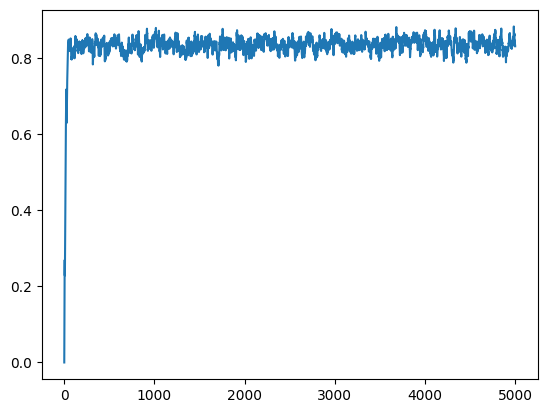

In [5]:
for j in range(1):
    print(j+1)
    obs = env.reset()
    powlst = [0.0]
    normpowlst = [0.0]
    for i in range(4999):
        action, _state = model.predict(obs)
        obs, rewards, done, info = env.step(action)
        powlst.append(float(info["Power"]))
        normpowlst.append(float(info["NormPower"]))
    plt.plot(normpowlst)
#     plt.plot(powlst)

In [18]:
reward = []
for j in range(1000):
    obs = env.reset()
    powlst = [0.0]
    normpowlst = [0.0]
    for i in range(499):
        action, _state = model.predict(obs)
        obs, rewards, done, info = env.step(action)
        powlst.append(float(info[0]["Power"]))
        normpowlst.append(float(info[0]["NormPower"]))
    reward.append(sum(normpowlst)/len(normpowlst)*100)
    print(j+1, reward[-1])

1 76.44550645202398
2 92.92246614024043
3 95.94043784886598
4 57.66243288367987
5 96.05912391245364
6 87.27504416406154
7 65.02707971334458
8 86.38626685142518
9 81.06952127888799
10 95.88412717282772
11 79.02952832281589
12 97.59290729016065
13 79.02734296917914
14 96.17202073782683
15 96.41272040456533
16 86.07322670072317
17 80.97755481749773
18 81.9078507810831
19 97.79961110502482
20 57.515441951155665
21 97.02889377623796
22 96.88752249777318
23 88.71240968704224
24 96.9531738743186
25 96.08688674718141
26 92.86859119087457
27 90.52642343342305
28 82.24099199473858
29 97.86241892278194
30 75.25518188178539
31 87.06963909119368
32 79.865069244802
33 89.6486555315554
34 97.49187786579132
35 79.12513040155173
36 71.38667179346085
37 86.02467276006936
38 80.64265203177929
39 64.78101734519005
40 92.27105650901794
41 82.26259206235409
42 96.44100834131241
43 89.44459579288959
44 89.84855469018221
45 95.41258721128106
46 71.39872559905052
47 63.94069614708424
48 93.96456104516983
49 87

381 88.52221014872194
382 93.95804611444474
383 88.52909255325794
384 91.19312064051628
385 96.7446721404791
386 85.88846164792776
387 96.93701789677142
388 67.12752495110036
389 90.7611333578825
390 78.23999483585358
391 92.60112247169018
392 94.78545689731837
393 51.62180676758289
394 61.78462510406971
395 98.12970208227635
396 66.25702241063118
397 91.86706330999732
398 69.49411099255084
399 96.63182872086763
400 58.625350159406665
401 88.94335200786591
402 80.06756017506123
403 92.23386955559253
404 86.72581282854081
405 70.97664057016372
406 58.70171633660794
407 65.88093232959508
408 95.48736285492778
409 91.25279952436685
410 97.13194618225097
411 51.6191741168499
412 68.09670851528644
413 79.31598059982062
414 73.68693641722203
415 94.58482500240206
416 85.9859547778964
417 81.0705041974783
418 90.78025860190392
419 47.56601004004479
420 95.59819608926773
421 94.13906342983246
422 86.42089121043682
423 78.77311112582683
424 97.76153279542923
425 55.77298081219196
426 90.5411760

756 95.81765547692775
757 23.64821788072586
758 87.29536561518908
759 54.53796537518502
760 95.51533518582582
761 80.60402128323912
762 84.38039477020503
763 67.61536048203706
764 82.01487287729978
765 87.95497827231884
766 93.81453772336245
767 22.76478658914566
768 79.64805963486434
769 74.35533822774887
770 90.7929348796606
771 96.72811286598444
772 72.47844618409871
773 71.44891600757838
774 90.95694173872471
775 98.26600166857243
776 41.11172930747271
777 82.49250721633435
778 73.11787641495467
779 76.4915191501379
780 95.4845017954707
781 90.35765453279019
782 86.0782000914216
783 90.5491743326187
784 94.41506410241128
785 71.07796705663205
786 84.05687673687935
787 59.5485959559679
788 88.29856573492289
789 67.7160892546177
790 94.798833861202
791 87.7888795517385
792 97.15410230904817
793 91.47788718938827
794 86.66337901800871
795 69.21729596853257
796 67.97618751525879
797 85.00993293523788
798 92.79388023614882
799 67.47211792767048
800 75.98044166862965
801 79.8470943585038

In [20]:
sum(reward)/len(reward)

82.50128275256364

In [17]:
normp = [0.0]
plst = [0.0]

obs = env.reset()
obs = env.render([8, 10, 6, 10, 5, 10, 25, 1000])

min_d = 0.01
delta_v_1 = 1
delta_v_2 = delta_v_1 / 3

Vk_ = 0
Ik_ = 0
Pk_ = 0

# action = 1
action = np.array([1.0], dtype='float32')

use_ppo = True

steps_ppo = 0
steps_ic = 0

last_pw = 0
step = 0
done = False

max_P = 0
max_V = 0

for _ in range(4999):
    if use_ppo:
        steps_ppo += 1

        if steps_ppo == 20:
            steps_ppo = 0
            use_ppo = False

        action_ppo, _states = model.predict(obs)
        obs, rewards, done, info = env.step(action_ppo)
        
    else:
        steps_ic += 1

        if steps_ic == 20:
            steps_ic = 0
            use_ppo = True

        obs, reward, done, info = env.step(action)

        Vk = info['Voltage']
        Ik = info['Current']
        Pk = info['Power']

        dV = Vk - Vk_
        dI = Ik - Ik_
        dP = Pk - Pk_

        Gk = (Ik / (Vk + 0.0001)) + (dI / (dV + 0.0001))
        Sk = np.abs(dP / (dV + 0.0001)) / (Ik + 0.0001)

        if np.abs(dV) < min_d:
            # dV == 0
            if np.abs(dI) < min_d:
                # dI == 0
                action = 0
            else:
                if dI > 0:
                    action = delta_v_1
                else:
                    action = -delta_v_2
        else:
            if np.abs(Gk) < min_d:
                # dG == 0
                action = 0
            else:
                if Gk > 0:
                    action = Sk * delta_v_1
                else:
                    if Sk < 1:
                        action = - Sk * delta_v_2
                    else:
                        action = - delta_v_2

        Vk_ = Vk
        Ik_ = Ik
        Pk_ = Pk
        action_ = action
        
    print(info['NormPower'])
    normp.append(info['NormPower'])
    plst.append(info['Power'])

[0.03659359]
[0.06204525]
[0.08153464]
[0.11251199]
[0.13872801]
[0.16410404]
[0.19433928]
[0.21797271]
[0.24767636]
[0.27933213]
[0.30450276]
[0.32894555]
[0.3481129]
[0.37237376]
[0.39819863]
[0.42425114]
[0.4534505]
[0.47071373]
[0.49406517]
[0.51552385]
[0.5210945]
[0.52646786]
[0.52469975]
[0.52993244]
[0.5282135]
[0.53329366]
[0.5316273]
[0.5365436]
[0.5349338]
[0.53967434]
[0.53812516]
[0.5426773]
[0.5411931]
[0.5455429]
[0.54412854]
[0.5482614]
[0.5469218]
[0.55082184]
[0.54956263]
[0.5532129]
[0.5636788]
[0.5624735]
[0.5625134]
[0.5535133]
[0.5471232]
[0.53683585]
[0.54155385]
[0.51023984]
[0.51046]
[0.5099964]
[0.5103787]
[0.5094408]
[0.5100563]
[0.509351]
[0.50451744]
[0.5088617]
[0.5068643]
[0.50452846]
[0.50596607]
[0.5069872]
[0.5076898]
[0.508045]
[0.50582945]
[0.5066494]
[0.50393116]
[0.50492364]
[0.5016718]
[0.5028475]
[0.49902886]
[0.500399]
[0.4959786]
[0.4975555]
[0.49249595]
[0.49429202]
[0.48855388]
[0.49058306]
[0.48412427]
[0.48640087]
[0.4791769]
[0.48171607]
[

[0.4588816]
[0.45455483]
[0.47235245]
[0.48059455]
[0.4828343]
[0.48095846]
[0.483778]
[0.49267444]
[0.4799696]
[0.4948237]
[0.49509883]
[0.48923013]
[0.49132875]
[0.4831612]
[0.49220964]
[0.5003616]
[0.49765897]
[0.5022924]
[0.49833524]
[0.49975386]
[0.49518356]
[0.49681172]
[0.49159318]
[0.493444]
[0.48753688]
[0.48962393]
[0.48298582]
[0.48532394]
[0.47790962]
[0.48051423]
[0.47227573]
[0.47516316]
[0.4660495]
[0.46923724]
[0.4591944]
[0.46270132]
[0.45167208]
[0.45551735]
[0.458044]
[0.46844178]
[0.47915068]
[0.47954276]
[0.4856272]
[0.49509186]
[0.49856004]
[0.4958483]
[0.49792504]
[0.49736163]
[0.4941236]
[0.49158898]
[0.49914053]
[0.489745]
[0.49700835]
[0.49739453]
[0.5000097]
[0.49530396]
[0.48960832]
[0.49236923]
[0.48625225]
[0.48841143]
[0.4815502]
[0.48396483]
[0.4763135]
[0.47899932]
[0.47050905]
[0.473483]
[0.46410227]
[0.46738154]
[0.45705515]
[0.46065915]
[0.44932866]
[0.4532776]
[0.44088092]
[0.44519562]
[0.43166706]
[0.43637034]
[0.4216402]
[0.42675588]
[0.4088427]
[

[0.79834414]
[0.6821456]
[0.80102175]
[0.7376496]
[0.78518087]
[0.7556368]
[0.77918136]
[0.78805196]
[0.77630055]
[0.7509896]
[0.7597752]
[0.7322981]
[0.7418285]
[0.7120484]
[0.7223689]
[0.6901455]
[0.70130444]
[0.6664862]
[0.6785363]
[0.6409643]
[0.65395916]
[0.62902623]
[0.6284403]
[0.63011014]
[0.62958336]
[0.63107175]
[0.63060683]
[0.63190544]
[0.63150513]
[0.65813714]
[0.6420569]
[0.6809174]
[0.6943192]
[0.6704754]
[0.7057598]
[0.6348034]
[0.72429174]
[0.692518]
[0.76969475]
[0.6902367]
[0.79502606]
[0.8008145]
[0.77256376]
[0.79121387]
[0.75412357]
[0.7834348]
[0.7773643]
[0.78268605]
[0.73880345]
[0.70864886]
[0.71910024]
[0.6864711]
[0.6977698]
[0.6625207]
[0.67471784]
[0.6366893]
[0.64984065]
[0.6292081]
[0.6286315]
[0.63027275]
[0.62975574]
[0.63121426]
[0.6307594]
[0.632027]
[0.6316372]
[0.63270473]
[0.6323832]
[0.63324183]
[0.6329915]
[0.6303462]
[0.6420348]
[0.6799452]
[0.6300309]
[0.72903657]
[0.6734895]
[0.75338715]
[0.7110164]
[0.7643779]
[0.74245155]
[0.7667148]
[0.748

[0.1535802]
[0.1528945]
[0.14822958]
[0.14902407]
[0.14901675]
[0.1537949]
[0.15395652]
[0.15442592]
[0.15626428]
[0.1584882]
[0.1592132]
[0.15784688]
[0.1603141]
[0.16080731]
[0.16026454]
[0.16078192]
[0.16200283]
[0.16218552]
[0.16236162]
[0.16238156]
[0.16161679]
[0.16190952]
[0.16091067]
[0.16128412]
[0.16003418]
[0.16049425]
[0.15897495]
[0.15952796]
[0.15771967]
[0.15837237]
[0.15625405]
[0.15701373]
[0.1545628]
[0.1554372]
[0.15262948]
[0.15362698]
[0.15043642]
[0.15156601]
[0.1479648]
[0.14923602]
[0.15303582]
[0.15217188]
[0.15163006]
[0.15341648]
[0.15280631]
[0.15170902]
[0.1538112]
[0.15187955]
[0.15351075]
[0.15266564]
[0.14953566]
[0.1531232]
[0.15487933]
[0.15003014]
[0.15319194]
[0.15137044]
[0.15383]
[0.15742472]
[0.15805249]
[0.15770583]
[0.15542114]
[0.1562383]
[0.15360862]
[0.15454471]
[0.1515452]
[0.15260889]
[0.1492126]
[0.15041313]
[0.14670676]
[0.14793862]
[0.14669812]
[0.1467124]
[0.14660731]
[0.14666328]
[0.14642924]
[0.14652947]
[0.14615852]
[0.14630575]
[0.1

[0.6286183]
[0.66684026]
[0.6906421]
[0.68971103]
[0.7346933]
[0.6931084]
[0.75288904]
[0.7321288]
[0.7353881]
[0.73418254]
[0.72180206]
[0.7428918]
[0.6708263]
[0.77322173]
[0.7035289]
[0.7730541]
[0.74154353]
[0.7585111]
[0.74271405]
[0.74472016]
[0.71531224]
[0.7255063]
[0.69367343]
[0.704698]
[0.6702953]
[0.6822026]
[0.645071]
[0.65791523]
[0.6288466]
[0.63172436]
[0.6299491]
[0.62941283]
[0.63093007]
[0.6304553]
[0.6317841]
[0.6313736]
[0.63250536]
[0.63216186]
[0.63308764]
[0.63281435]
[0.6299336]
[0.62865514]
[0.70981175]
[0.63007605]
[0.6942211]
[0.63128966]
[0.66880876]
[0.6925342]
[0.66007495]
[0.72029567]
[0.62916124]
[0.7635018]
[0.6297556]
[0.7654702]
[0.6525545]
[0.7491259]
[0.63621503]
[0.7819171]
[0.78721434]
[0.7375523]
[0.7072386]
[0.7177444]
[0.6849469]
[0.6963032]
[0.6608761]
[0.6731345]
[0.63491607]
[0.6481325]
[0.62928206]
[0.6287094]
[0.63033867]
[0.6298257]
[0.63127196]
[0.63082135]
[0.63207585]
[0.6316905]
[0.63274467]
[0.6324278]
[0.6332722]
[0.6330266]
[0.629

[0.6322101]
[0.6305888]
[0.6383213]
[0.7082669]
[0.6300122]
[0.7121609]
[0.6917165]
[0.72143096]
[0.628906]
[0.75298244]
[0.62847275]
[0.78455436]
[0.63878226]
[0.79022443]
[0.70642483]
[0.80004615]
[0.72092044]
[0.8063592]
[0.7659941]
[0.8310765]
[0.8134611]
[0.8196073]
[0.80029494]
[0.8070226]
[0.78591067]
[0.7932561]
[0.77023405]
[0.7782351]
[0.7531845]
[0.76188165]
[0.7346783]
[0.74411464]
[0.71462536]
[0.724846]
[0.6929307]
[0.70398414]
[0.6694939]
[0.6814309]
[0.64420635]
[0.65708184]
[0.6285156]
[0.7172326]
[0.6427146]
[0.7551064]
[0.6314371]
[0.7716775]
[0.7254097]
[0.78150946]
[0.7707951]
[0.7858943]
[0.75596964]
[0.8058006]
[0.78846246]
[0.80376786]
[0.745315]
[0.7794693]
[0.6943697]
[0.7983715]
[0.70700485]
[0.79987425]
[0.77778]
[0.78546745]
[0.7613867]
[0.7697512]
[0.74357706]
[0.7526603]
[0.7242635]
[0.73410946]
[0.7033548]
[0.71400976]
[0.6807504]
[0.6922653]
[0.65634793]
[0.6687746]
[0.63003665]
[0.64343166]
[0.629481]
[0.6289188]
[0.6305158]
[0.6300139]
[0.6814648]
[0.

[0.43944287]
[0.44267285]
[0.4644769]
[0.46344933]
[0.46724063]
[0.48144177]
[0.47869962]
[0.48462814]
[0.48159426]
[0.47637182]
[0.48945644]
[0.4957666]
[0.4946177]
[0.5003142]
[0.4974463]
[0.49539065]
[0.5011864]
[0.5043202]
[0.501965]
[0.49462268]
[0.48895276]
[0.49095896]
[0.4845713]
[0.48682323]
[0.47967508]
[0.48218817]
[0.47423208]
[0.47702247]
[0.46820876]
[0.4712937]
[0.46156925]
[0.46496668]
[0.45427513]
[0.4580046]
[0.44628674]
[0.45036837]
[0.43756044]
[0.44201654]
[0.4280514]
[0.43290448]
[0.45176816]
[0.44160977]
[0.46865013]
[0.47872105]
[0.49289563]
[0.48908654]
[0.4818512]
[0.47233063]
[0.48037636]
[0.4814246]
[0.48076156]
[0.48627982]
[0.48349667]
[0.48624286]
[0.4776399]
[0.48062623]
[0.4805549]
[0.48087034]
[0.48887023]
[0.48941725]
[0.48274004]
[0.48509127]
[0.47763625]
[0.48025465]
[0.47197276]
[0.47487524]
[0.46571544]
[0.4689192]
[0.45882764]
[0.46235102]
[0.45126998]
[0.4551331]
[0.4430011]
[0.44722506]
[0.4339777]
[0.43858466]
[0.42415267]
[0.4291659]
[0.41347

C:\Users\archi\anaconda3\envs\BTPtorch\lib\site-packages\numpy\core\shape_base.py:65: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = asanyarray(ary)


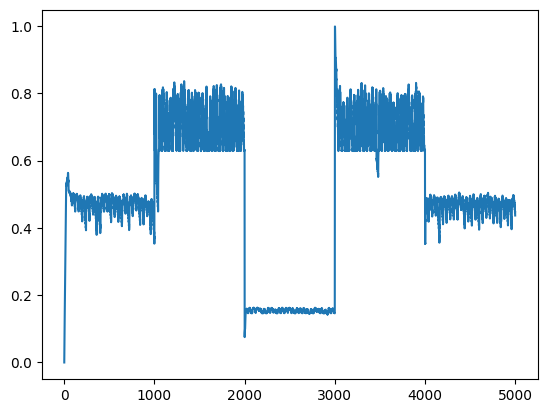

In [18]:
plt.plot(normp)

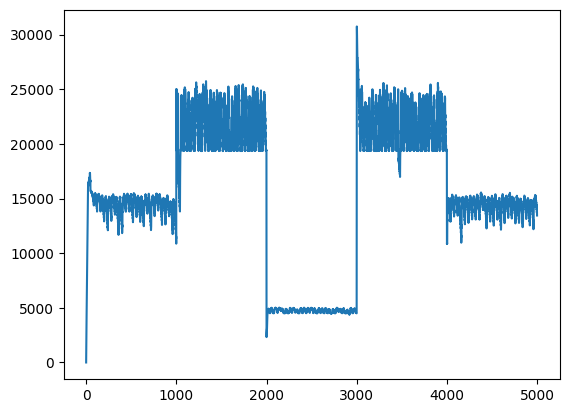

In [19]:
plt.plot(plst)

In [25]:
np.save('1_irrtemp_PPO.npy', plst)

In [10]:
import random

rew = []
timelst = []

for x in range(100):
    
    start_time = time.time()
    
    normp = []
    plst = []

    obs = env.reset()
    a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    obs = env.render([a, 10, b, 10, c, 10, 25, 1000])
#     obs = env.render([8, 10, 6, 10, 5, 10, 25, 1000])

    min_d = 0.01
    delta_v_1 = 1
    delta_v_2 = delta_v_1 / 3

    Vk_ = 0
    Ik_ = 0
    Pk_ = 0

    # action = 1
    action = np.array([1.0], dtype='float32')

    use_ppo = True

    steps_ppo = 0
    steps_ic = 0

    last_pw = 0
    step = 0
    done = False

    max_P = 0
    max_V = 0

    for _ in range(1000):
        if use_ppo:
            steps_ppo += 1

            if steps_ppo == 20:
                steps_ppo = 0
                use_ppo = False

            action_ppo, _states = model.predict(obs)
            obs, rewards, done, info = env.step(action_ppo)

        else:
            steps_ic += 1

            if steps_ic == 20:
                steps_ic = 0
                use_ppo = True

            obs, reward, done, info = env.step(action)

            Vk = info['Voltage']
            Ik = info['Current']
            Pk = info['Power']

            dV = Vk - Vk_
            dI = Ik - Ik_
            dP = Pk - Pk_

            Gk = (Ik / (Vk + 0.0001)) + (dI / (dV + 0.0001))
            Sk = np.abs(dP / (dV + 0.0001)) / (Ik + 0.0001)

            if np.abs(dV) < min_d:
                # dV == 0
                if np.abs(dI) < min_d:
                    # dI == 0
                    action = 0
                else:
                    if dI > 0:
                        action = delta_v_1
                    else:
                        action = -delta_v_2
            else:
                if np.abs(Gk) < min_d:
                    # dG == 0
                    action = 0
                else:
                    if Gk > 0:
                        action = Sk * delta_v_1
                    else:
                        if Sk < 1:
                            action = - Sk * delta_v_2
                        else:
                            action = - delta_v_2

            Vk_ = Vk
            Ik_ = Ik
            Pk_ = Pk
            action_ = action

#         print(info['NormPower'])
        normp.append(info['NormPower'])
        plst.append(info['Power'])
    
    rew.append(float(sum(normp[200:1000])/8))
    
    end_time = time.time()
    timelst.append(end_time - start_time)
    print(x, rew[-1], end_time - start_time)

0 68.18451690673828 1.0619990825653076
1 97.22879791259766 3.875000476837158
2 93.8088150024414 6.872000455856323
3 96.97445678710938 3.6515164375305176
4 37.337379455566406 1.1240007877349854
5 62.396419525146484 4.279003143310547


c:\users\archi\python code\btp\ppo_new_win\mppt-gym_v4\gym_mppt\envs\mppt_env_shaded3.py:41: RuntimeWarning: overflow encountered in exp
  I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)
c:\users\archi\python code\btp\ppo_new_win\mppt-gym_v4\gym_mppt\envs\mppt_env_shaded3.py:57: RuntimeWarning: invalid value encountered in subtract
  In = I - fv/fdv


6 33.531402587890625 3.626103401184082
7 93.93673706054688 5.023766040802002
8 85.36717987060547 3.6592588424682617
9 88.05204772949219 2.8200018405914307
10 91.6024169921875 1.1559991836547852
11 72.32366180419922 1.1830017566680908
12 88.20899200439453 4.6569976806640625
13 87.1970443725586 1.1160016059875488
14 77.80490112304688 3.4629979133605957
15 99.5243148803711 3.967998504638672
16 68.4736328125 1.7220032215118408
17 88.8063735961914 1.0709986686706543
18 84.57015991210938 1.136000156402588
19 96.49403381347656 2.205522060394287
20 81.37533569335938 3.4429986476898193
21 94.61582946777344 1.0349986553192139
22 99.60427856445312 3.2099995613098145
23 70.11576080322266 1.0860002040863037
24 76.96002197265625 1.1209988594055176
25 81.59028625488281 1.0919997692108154
26 83.54530334472656 3.8670053482055664
27 97.76506805419922 1.5229949951171875
28 65.7781982421875 2.9560022354125977
29 90.38684844970703 1.0080018043518066
30 98.43183135986328 1.2559995651245117
31 99.52973175048

In [11]:
((sum(timelst) / 100) / 1000) * 1000

2.6256957912445067

In [7]:
sum(rew)/len(rew)

76.0087731552124

In [8]:
import statistics
statistics.stdev(rew)

19.267245694213205

In [5]:
import random

powlst = np.zeros((100), dtype=object)
shading = np.zeros((100), dtype=object)

for x in range(100):
    
    normp = []
    plst = []

    obs = env.reset()
    a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
    obs = env.render([a, 10, b, 10, c, 10, 25, 1000])
#     obs = env.render([8, 10, 6, 10, 5, 10, 25, 1000])

    min_d = 0.01
    delta_v_1 = 1
    delta_v_2 = delta_v_1 / 3

    Vk_ = 0
    Ik_ = 0
    Pk_ = 0

    # action = 1
    action = np.array([1.0], dtype='float32')

    use_ppo = True

    steps_ppo = 0
    steps_ic = 0

    last_pw = 0
    step = 0
    done = False

    max_P = 0
    max_V = 0

    for _ in range(4999):
        if use_ppo:
            steps_ppo += 1

            if steps_ppo == 20:
                steps_ppo = 0
                use_ppo = False

            action_ppo, _states = model.predict(obs)
            obs, rewards, done, info = env.step(action_ppo)

        else:
            steps_ic += 1

            if steps_ic == 20:
                steps_ic = 0
                use_ppo = True

            obs, reward, done, info = env.step(action)

            Vk = info['Voltage']
            Ik = info['Current']
            Pk = info['Power']

            dV = Vk - Vk_
            dI = Ik - Ik_
            dP = Pk - Pk_

            Gk = (Ik / (Vk + 0.0001)) + (dI / (dV + 0.0001))
            Sk = np.abs(dP / (dV + 0.0001)) / (Ik + 0.0001)

            if np.abs(dV) < min_d:
                # dV == 0
                if np.abs(dI) < min_d:
                    # dI == 0
                    action = 0
                else:
                    if dI > 0:
                        action = delta_v_1
                    else:
                        action = -delta_v_2
            else:
                if np.abs(Gk) < min_d:
                    # dG == 0
                    action = 0
                else:
                    if Gk > 0:
                        action = Sk * delta_v_1
                    else:
                        if Sk < 1:
                            action = - Sk * delta_v_2
                        else:
                            action = - delta_v_2

            Vk_ = Vk
            Ik_ = Ik
            Pk_ = Pk
            action_ = action

#         print(info['NormPower'])
        normp.append(info['NormPower'])
        plst.append(info['Power'])
    
    powlst[x] = plst
    shading[x] = info['Shading']
    
    print(x, shading[x])
#     rew.append(float(sum(normp[200:1000])/8))
#     print(x, rew[-1])

0 [9, 10, 1, 10, 4, 10]
1 [10, 10, 5, 10, 3, 10]
2 [1, 10, 5, 10, 3, 10]
3 [4, 10, 9, 10, 3, 10]
4 [7, 10, 6, 10, 2, 10]
5 [8, 10, 7, 10, 3, 10]
6 [9, 10, 3, 10, 1, 10]
7 [7, 10, 1, 10, 3, 10]
8 [9, 10, 6, 10, 8, 10]
9 [6, 10, 2, 10, 10, 10]
10 [4, 10, 6, 10, 8, 10]
11 [6, 10, 7, 10, 8, 10]
12 [10, 10, 6, 10, 10, 10]
13 [6, 10, 4, 10, 10, 10]
14 [1, 10, 3, 10, 9, 10]
15 [2, 10, 2, 10, 6, 10]
16 [3, 10, 6, 10, 2, 10]
17 [2, 10, 2, 10, 6, 10]
18 [4, 10, 5, 10, 5, 10]
19 [8, 10, 8, 10, 7, 10]
20 [1, 10, 5, 10, 4, 10]
21 [2, 10, 2, 10, 1, 10]
22 [8, 10, 10, 10, 8, 10]
23 [7, 10, 4, 10, 5, 10]
24 [7, 10, 8, 10, 8, 10]
25 [1, 10, 7, 10, 6, 10]
26 [4, 10, 7, 10, 8, 10]
27 [10, 10, 8, 10, 5, 10]
28 [5, 10, 8, 10, 3, 10]
29 [10, 10, 3, 10, 7, 10]
30 [2, 10, 8, 10, 1, 10]
31 [7, 10, 5, 10, 9, 10]
32 [10, 10, 2, 10, 9, 10]
33 [6, 10, 4, 10, 2, 10]
34 [1, 10, 4, 10, 4, 10]
35 [2, 10, 1, 10, 10, 10]
36 [3, 10, 1, 10, 1, 10]
37 [5, 10, 10, 10, 2, 10]
38 [6, 10, 2, 10, 9, 10]
39 [7, 10, 8, 10, 3, 10]

c:\users\archi\python code\btp\ppo_new_win\mppt-gym_v4\gym_mppt\envs\mppt_env_shaded3.py:41: RuntimeWarning: overflow encountered in exp
  I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)
c:\users\archi\python code\btp\ppo_new_win\mppt-gym_v4\gym_mppt\envs\mppt_env_shaded3.py:57: RuntimeWarning: invalid value encountered in subtract
  In = I - fv/fdv


77 [6, 10, 7, 10, 1, 10]
78 [9, 10, 7, 10, 5, 10]
79 [2, 10, 3, 10, 8, 10]
80 [4, 10, 7, 10, 9, 10]
81 [6, 10, 1, 10, 4, 10]
82 [3, 10, 4, 10, 10, 10]
83 [8, 10, 4, 10, 10, 10]
84 [9, 10, 3, 10, 3, 10]
85 [1, 10, 3, 10, 3, 10]
86 [8, 10, 8, 10, 6, 10]
87 [4, 10, 5, 10, 7, 10]
88 [2, 10, 6, 10, 2, 10]
89 [1, 10, 1, 10, 10, 10]
90 [5, 10, 7, 10, 7, 10]
91 [4, 10, 7, 10, 1, 10]
92 [6, 10, 3, 10, 3, 10]
93 [10, 10, 4, 10, 10, 10]
94 [1, 10, 8, 10, 5, 10]
95 [7, 10, 2, 10, 2, 10]
96 [6, 10, 10, 10, 6, 10]
97 [7, 10, 4, 10, 7, 10]
98 [8, 10, 1, 10, 10, 10]
99 [10, 10, 3, 10, 9, 10]


In [6]:
gmpp = np.load('irrtempgmpp.npy', allow_pickle=True)

In [7]:
errormean = []

for i in range(100):
    lst = powlst[i]
      
    errori = sum([100-((i-j)/i*100) if i != 0 else None for i,j in zip(gmpp[shading[i][0]][shading[i][2]][shading[i][4]][200:5000],lst[200:5000])])/4800
    
    print(shading[i], float(errori), sep = ', ', end = '\n')
    errormean.append(float(errori))

[9, 10, 1, 10, 4, 10], 86.18131256103516
[10, 10, 5, 10, 3, 10], 82.97972106933594
[1, 10, 5, 10, 3, 10], 76.08938598632812
[4, 10, 9, 10, 3, 10], 85.36011505126953
[7, 10, 6, 10, 2, 10], 83.07140350341797
[8, 10, 7, 10, 3, 10], 90.2289810180664
[9, 10, 3, 10, 1, 10], 85.50304412841797
[7, 10, 1, 10, 3, 10], 94.48238372802734
[9, 10, 6, 10, 8, 10], 86.0648422241211
[6, 10, 2, 10, 10, 10], 87.32930755615234
[4, 10, 6, 10, 8, 10], 80.05865478515625
[6, 10, 7, 10, 8, 10], 78.6920394897461
[10, 10, 6, 10, 10, 10], 90.13972473144531
[6, 10, 4, 10, 10, 10], 82.0497817993164
[1, 10, 3, 10, 9, 10], 80.42866516113281
[2, 10, 2, 10, 6, 10], 83.91384887695312
[3, 10, 6, 10, 2, 10], 92.94403839111328
[2, 10, 2, 10, 6, 10], 83.8870849609375
[4, 10, 5, 10, 5, 10], 46.07133865356445
[8, 10, 8, 10, 7, 10], 88.24372100830078
[1, 10, 5, 10, 4, 10], 61.097557067871094
[2, 10, 2, 10, 1, 10], 31.39859962463379
[8, 10, 10, 10, 8, 10], 91.28785705566406
[7, 10, 4, 10, 5, 10], 71.94461822509766
[7, 10, 8, 10,

In [8]:
errormean

[86.18131256103516,
 82.97972106933594,
 76.08938598632812,
 85.36011505126953,
 83.07140350341797,
 90.2289810180664,
 85.50304412841797,
 94.48238372802734,
 86.0648422241211,
 87.32930755615234,
 80.05865478515625,
 78.6920394897461,
 90.13972473144531,
 82.0497817993164,
 80.42866516113281,
 83.91384887695312,
 92.94403839111328,
 83.8870849609375,
 46.07133865356445,
 88.24372100830078,
 61.097557067871094,
 31.39859962463379,
 91.28785705566406,
 71.94461822509766,
 87.3630599975586,
 90.49824523925781,
 94.21173858642578,
 93.81682586669922,
 77.9217758178711,
 94.78828430175781,
 89.66914367675781,
 83.54525756835938,
 89.49794006347656,
 73.59327697753906,
 40.351280212402344,
 78.24205017089844,
 36.288429260253906,
 80.3046646118164,
 88.25497436523438,
 91.218994140625,
 50.95532989501953,
 83.72058868408203,
 88.61249542236328,
 87.8798599243164,
 64.69268798828125,
 78.033935546875,
 83.07611083984375,
 93.40963745117188,
 72.11396789550781,
 92.9765853881836,
 81.9937896

In [9]:
sum(errormean)/len(errormean)

82.05678709030151

In [10]:
import statistics
statistics.stdev(errormean)

15.295834303671922